## PREDICCIÓN DE RETORNOS — LSTM

Fase 7 — Un modelo LSTM por activo, usando ventanas de tiempo (secuencias) en vez de observaciones independientes como en SVR, para capturar dependencias temporales en los datos.

### Diferencia clave frente a SVR

SVR trata cada fila del dataset como independiente: mira el RSI, MACD, etc. de *un solo día* y predice el retorno futuro. LSTM en cambio recibe una **secuencia** de los últimos N días de esas mismas variables, y aprende patrones que dependen del orden temporal — por ejemplo, una tendencia que se viene formando a lo largo de varias sesiones, no solo el valor de hoy.

Importación de librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)
np.random.seed(42)


In [2]:
# ============================================================
# CONFIGURACIÓN
# ============================================================

PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data" / "processed_diversified"
RESULTS_DIR = PROJECT_ROOT / "results" / "lstm_diversified"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

SECTOR_MAP_FILE = DATA_DIR / "sector_map.csv"
FEATURES_FILE = DATA_DIR / "features_dataset.csv"  # mismo dataset de horizonte 5 días que usó SVR, para comparar en igualdad de condiciones

TRAIN_TEST_SPLIT_DATE = "2024-01-01"
SEQUENCE_LENGTH = 20  # días de historia que ve el modelo para hacer cada predicción

FEATURE_COLS = [
    "return_1d", "return_5d", "return_10d", "return_21d", "return_63d",
    "sma_10", "sma_20", "sma_50",
    "ema_10", "ema_20", "ema_50",
    "vol_10", "vol_20", "vol_50",
    "rsi_14", "macd", "macd_signal",
    "bb_high", "bb_low"
]

TARGET_COL = "target_return_5d"
benchmark = "^GSPC"
MAX_WEIGHT = 0.15
MAX_WEIGHT_TWO = 0.10
MIN_WEIGHT = 0.01  # misma cota mínima que en SVR/Markowitz diversified. Si la cambias (p. ej. 0.005), cámbiala también allá y los nombres de columnas "min1%" de abajo

print("Longitud de secuencia:", SEQUENCE_LENGTH, "días")
print("Directorio de resultados:", RESULTS_DIR)


Longitud de secuencia: 20 días
Directorio de resultados: c:\Users\ofeli\Documents\GitHub\Portafolio_investigacion\results\lstm_diversified


## Carga del dataset (mismo de la Fase 4 / Fase 6, horizonte 5 días)

In [3]:
dataset = pd.read_csv(FEATURES_FILE, parse_dates=["Date"])
tickers = [t for t in sorted(dataset["ticker"].unique()) if t != benchmark]

print("Activos:", len(tickers))
dataset.head()


Activos: 44


,Date,ticker,return_5d,return_10d,return_21d,return_63d,return_1d,sma_10,sma_20,sma_50,...,vol_10,vol_20,vol_50,rsi_14,macd,macd_signal,bb_high,bb_low,target_return_5d,sector
0,2018-04-05,AAPL,0.037962,0.008933,-0.021906,0.007400,0.006934,39.600018,40.618840,40.054936,...,0.350189,0.277843,0.295302,51.668483,-0.258640,-0.196719,43.021589,38.216092,0.007755,Tecnología
1,2018-04-06,AAPL,0.003576,-0.002784,-0.037994,-0.022906,-0.025578,39.588996,40.518471,40.030863,...,0.368380,0.287978,0.298714,44.927486,-0.282604,-0.213896,42.934290,38.102651,0.037712,Tecnología
2,2018-04-09,AAPL,0.020219,0.030981,-0.038940,-0.024324,0.009918,39.708830,40.402037,40.029150,...,0.347061,0.282557,0.296884,47.703689,-0.266918,-0.224500,42.702875,38.101199,0.033931,Tecnología
3,2018-04-10,AAPL,0.028861,0.002778,-0.037394,-0.002258,0.018818,39.720085,40.302722,40.040577,...,0.264977,0.289640,0.299806,52.631114,-0.191725,-0.217945,42.372829,38.232614,0.028803,Tecnología
4,2018-04-11,AAPL,0.004836,0.024356,-0.051068,-0.006809,-0.004675,39.816234,40.214429,40.064788,...,0.225192,0.288492,0.296126,51.313265,-0.145779,-0.203512,42.094462,38.334396,0.031315,Tecnología


### Mapeo de sectores

Carga el mapeo ticker → sector generado por `data_pipeline_diversified.py`, y define una paleta de colores por sector y una función para agrupar pesos por sector (se usan más abajo).

In [4]:
sector_map = pd.read_csv(SECTOR_MAP_FILE)
ticker_to_sector = dict(zip(sector_map["ticker"], sector_map["sector"]))

sectors = sorted(sector_map["sector"].unique())
cmap = plt.get_cmap("tab20")
sector_to_color = {sector: cmap(k / len(sectors)) for k, sector in enumerate(sectors)}

def weights_by_sector(weights: dict) -> pd.Series:
    w = pd.Series(weights)
    grouped = w.groupby(w.index.map(lambda t: ticker_to_sector.get(t, "Otro"))).sum()
    return grouped.sort_values(ascending=False)

print("Sectores:", len(sectors))


Sectores: 11


## Función para construir secuencias

A diferencia de SVR (donde cada fila es una observación independiente), aquí cada muestra de entrenamiento es una **ventana de `SEQUENCE_LENGTH` días consecutivos** de todas las features, y la etiqueta es el target del último día de esa ventana.

In [5]:
def build_sequences(df: pd.DataFrame, feature_cols: list, target_col: str, seq_len: int):
    X_seq, y_seq, dates_seq = [], [], []

    features = df[feature_cols].values
    targets = df[target_col].values
    dates = df["Date"].values

    for i in range(seq_len, len(df)):
        X_seq.append(features[i - seq_len:i])
        y_seq.append(targets[i])
        dates_seq.append(dates[i])

    return np.array(X_seq), np.array(y_seq), np.array(dates_seq)


## Entrenamiento: un LSTM por activo

Mismo criterio que en SVR (Fase 6): escalado ajustado solo con datos de entrenamiento, split temporal (no aleatorio), y evaluación en el periodo de test. Se reserva un 15% del train como conjunto de **validación** (`validation_split=0.15`), y `EarlyStopping` vigila la pérdida de validación (`val_loss`), no la de entrenamiento — así el entrenamiento se detiene en el punto donde el modelo generaliza mejor, en vez de seguir ajustando hasta memorizar ruido del propio train. La arquitectura es intencionalmente simple (dos capas LSTM + dropout) para evitar sobreajuste dado el tamaño moderado de los datos por activo.

In [6]:
EPOCHS = 50
BATCH_SIZE = 32

results = []
predictions = {}
histories = {}

for ticker in tickers:

    df_t = dataset[dataset["ticker"] == ticker].sort_values("Date").reset_index(drop=True)

    if len(df_t) < SEQUENCE_LENGTH + 100:
        print(f"{ticker}: datos insuficientes, se omite")
        continue

    train_t = df_t[df_t["Date"] < TRAIN_TEST_SPLIT_DATE]
    test_t = df_t[df_t["Date"] >= TRAIN_TEST_SPLIT_DATE]

    scaler_X = StandardScaler()
    scaler_X.fit(train_t[FEATURE_COLS])

    scaler_y = StandardScaler()
    scaler_y.fit(train_t[[TARGET_COL]])

    df_t_scaled = df_t.copy()
    df_t_scaled[FEATURE_COLS] = scaler_X.transform(df_t[FEATURE_COLS])
    df_t_scaled[TARGET_COL] = scaler_y.transform(df_t[[TARGET_COL]])

    train_scaled = df_t_scaled[df_t_scaled["Date"] < TRAIN_TEST_SPLIT_DATE]
    combined_for_test = df_t_scaled[df_t_scaled["Date"] < test_t["Date"].min()].tail(SEQUENCE_LENGTH)
    test_scaled = pd.concat([combined_for_test, df_t_scaled[df_t_scaled["Date"] >= TRAIN_TEST_SPLIT_DATE]])

    X_train, y_train, _ = build_sequences(train_scaled, FEATURE_COLS, TARGET_COL, SEQUENCE_LENGTH)
    X_test, y_test_scaled, dates_test = build_sequences(test_scaled, FEATURE_COLS, TARGET_COL, SEQUENCE_LENGTH)

    model = Sequential([
        LSTM(32, return_sequences=True, input_shape=(SEQUENCE_LENGTH, len(FEATURE_COLS))),
        Dropout(0.2),
        LSTM(16),
        Dropout(0.2),
        Dense(1)
    ])
    model.compile(optimizer="adam", loss="mse")

    early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

    history = model.fit(
        X_train, y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=0.15,
        callbacks=[early_stop],
        verbose=0
    )

    y_pred_scaled = model.predict(X_test, verbose=0).ravel()
    y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
    y_test = scaler_y.inverse_transform(y_test_scaled.reshape(-1, 1)).ravel()

    rmse = mean_squared_error(y_test, y_pred) ** 0.5
    r2 = r2_score(y_test, y_pred)

    predictions[ticker] = pd.DataFrame({
        "Date": dates_test,
        "actual": y_test,
        "predicted": y_pred
    })
    histories[ticker] = {"loss": history.history["loss"], "val_loss": history.history["val_loss"]}

    results.append({
        "ticker": ticker,
        "epochs_entrenados": len(history.history["loss"]),
        "RMSE": rmse,
        "R2": r2
    })

    print(f"{ticker}: RMSE={rmse:.5f}  R2={r2:.4f}  (entrenado {len(history.history['loss'])} épocas)")

results_df = pd.DataFrame(results).set_index("ticker")


c:\Users\ofeli\anaconda3\envs\Finance\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


AAPL: RMSE=0.05108  R2=-0.6526  (entrenado 10 épocas)


c:\Users\ofeli\anaconda3\envs\Finance\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


ABBV: RMSE=0.03720  R2=-0.0281  (entrenado 6 épocas)


c:\Users\ofeli\anaconda3\envs\Finance\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


...

V: RMSE=0.02846  R2=-0.1093  (entrenado 6 épocas)


c:\Users\ofeli\anaconda3\envs\Finance\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


WMT: RMSE=0.03694  R2=-0.2747  (entrenado 6 épocas)


c:\Users\ofeli\anaconda3\envs\Finance\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


XOM: RMSE=0.03388  R2=-0.0257  (entrenado 6 épocas)


## Tabla resumen de desempeño por activo

In [7]:
results_df.sort_values("R2", ascending=False).round(5)


,epochs_entrenados,RMSE,R2
ticker,,,
AMT,6,0.03542,-0.00787
APD,6,0.03784,-0.01196
HON,6,0.03322,-0.01335
LLY,7,0.05157,-0.01404
MSFT,6,0.04032,-0.01543
XOM,6,0.03388,-0.02572
EQIX,6,0.03499,-0.02686
ABBV,6,0.03720,-0.02807
JPM,6,0.03217,-0.03252


## Comparación directa: SVR vs. LSTM (mismo horizonte, 5 días)

Este es el resultado central de la Fase 7: ¿la arquitectura secuencial de LSTM captura señal que SVR no pudo?

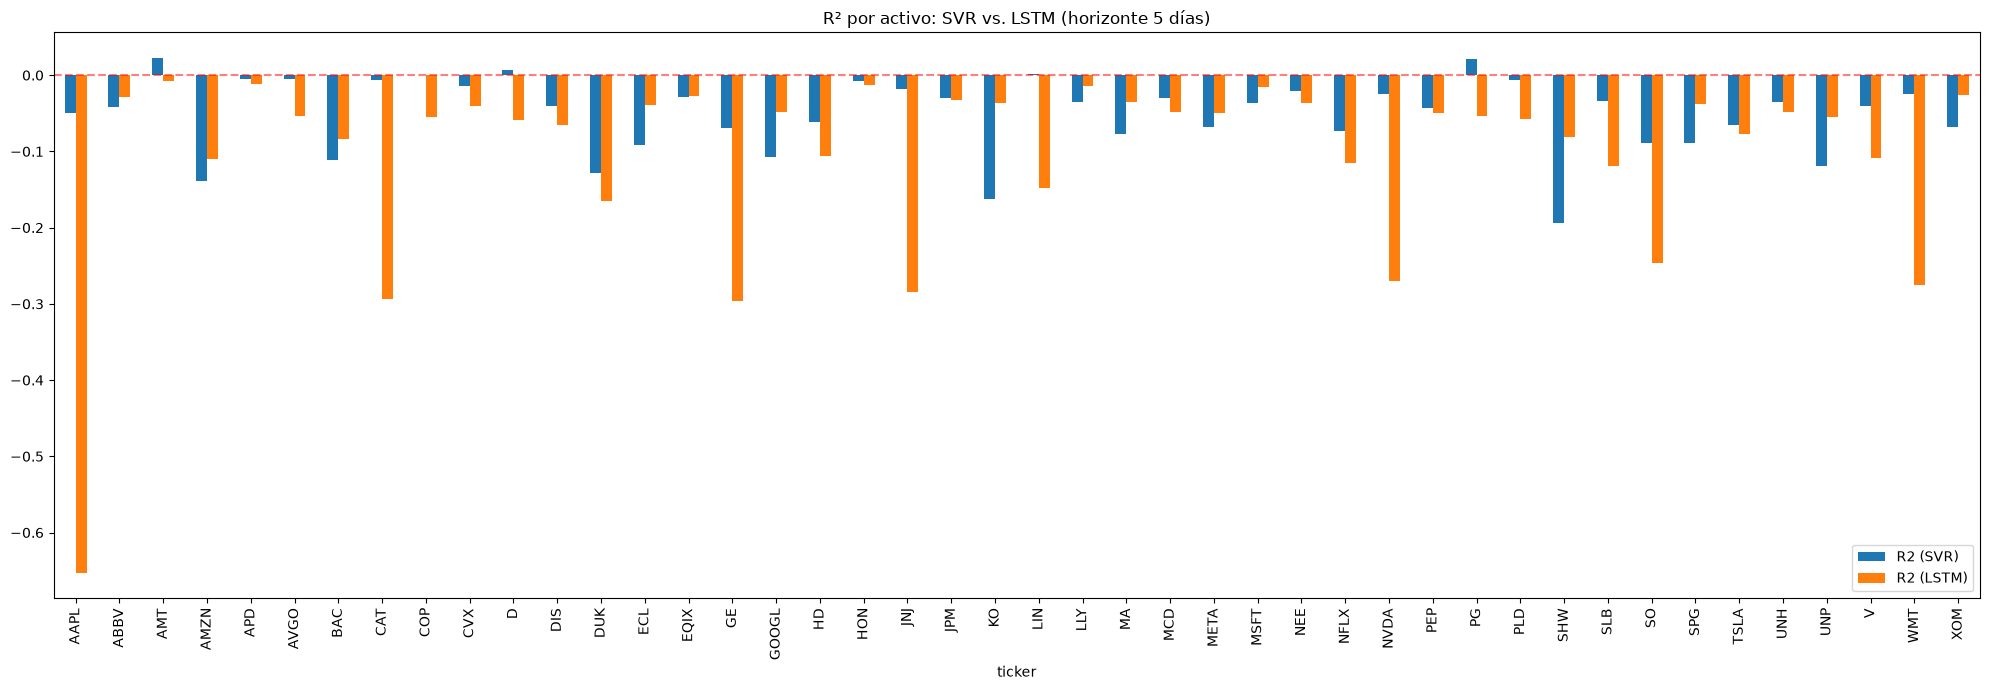

Promedio R2 SVR: -0.0509
Promedio R2 LSTM: -0.1017


In [8]:
RESULTS_SVR_FILE = PROJECT_ROOT / "results" / "svr_diversified" / "svr_performance_by_ticker.csv"

if RESULTS_SVR_FILE.exists():
    results_svr = pd.read_csv(RESULTS_SVR_FILE, index_col="ticker")

    r2_comparison = pd.DataFrame({
        "R2 (SVR)": results_svr["R2"],
        "R2 (LSTM)": results_df["R2"]
    }).dropna()

    r2_comparison.plot(kind="bar", figsize=(20, 7), title="R² por activo: SVR vs. LSTM (horizonte 5 días)")
    plt.axhline(0, color="red", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "01_r2_svr_vs_lstm.png", dpi=300, bbox_inches="tight")
    plt.show()

    print("Promedio R2 SVR:", r2_comparison['R2 (SVR)'].mean().round(4))
    print("Promedio R2 LSTM:", r2_comparison['R2 (LSTM)'].mean().round(4))
else:
    print("No se encontró", RESULTS_SVR_FILE, "— corre primero 05_svr_diversified.ipynb para poder comparar.")


### R² promedio por sector: SVR vs. LSTM

Pregunta propia del experimento diversificado: ¿alguno de los dos modelos predice mejor en ciertos sectores? (La columna de SVR aparece solo si ya corriste `05_svr_diversified.ipynb`.)

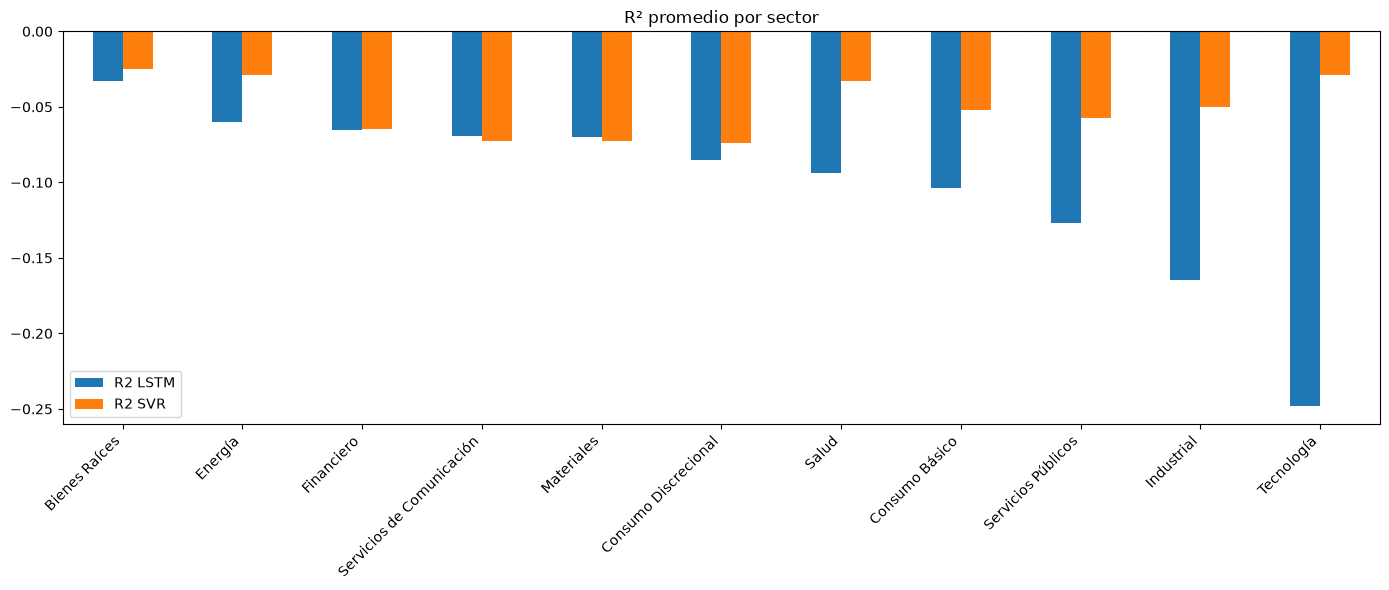

,R2 LSTM,R2 SVR
Bienes Raíces,-0.0326,-0.0252
Energía,-0.0599,-0.0292
Financiero,-0.0650,-0.0648
Servicios de Comunicación,-0.0693,-0.0724
Materiales,-0.0700,-0.0726
Consumo Discrecional,-0.0854,-0.0741
Salud,-0.0939,-0.0328
Consumo Básico,-0.1038,-0.0520
Servicios Públicos,-0.1266,-0.0573
Industrial,-0.1646,-0.0504


In [9]:
lstm_sector = pd.Series({t: ticker_to_sector.get(t, "Otro") for t in results_df.index})
r2_sector = pd.DataFrame({"R2 LSTM": results_df["R2"].groupby(lstm_sector).mean()})

if RESULTS_SVR_FILE.exists():
    svr_sector = pd.Series({t: ticker_to_sector.get(t, "Otro") for t in results_svr.index})
    r2_sector["R2 SVR"] = results_svr["R2"].groupby(svr_sector).mean()

r2_sector = r2_sector.sort_values("R2 LSTM", ascending=False)

r2_sector.plot(kind="bar", figsize=(14, 6), title="R² promedio por sector")
plt.axhline(0, color="red", linestyle="--", alpha=0.5)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "01b_r2_por_sector.png", dpi=300, bbox_inches="tight")
plt.show()

r2_sector.round(4)


## Curvas de pérdida (ejemplo) — chequeo de sobreajuste

Ahora se grafican **entrenamiento y validación juntas**. Si la pérdida de validación deja de bajar (o empieza a subir) mientras la de entrenamiento sigue bajando, es la señal clásica de sobreajuste — y es justo lo que `EarlyStopping` sobre `val_loss` debería estar evitando ahora.

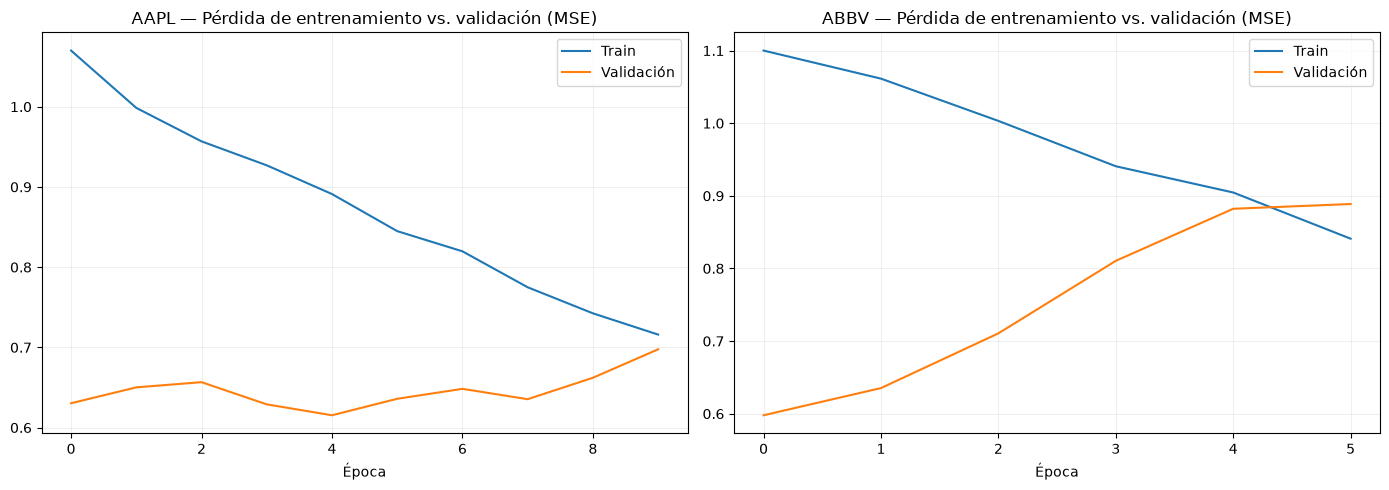

In [10]:
example_tickers = list(histories.keys())[:2]

fig, axes = plt.subplots(1, len(example_tickers), figsize=(14, 5))

for ax, ticker in zip(axes, example_tickers):
    ax.plot(histories[ticker]["loss"], label="Train")
    ax.plot(histories[ticker]["val_loss"], label="Validación")
    ax.set_title(f"{ticker} — Pérdida de entrenamiento vs. validación (MSE)")
    ax.set_xlabel("Época")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "02_curvas_perdida.png", dpi=300, bbox_inches="tight")
plt.show()


## Predicho vs. real — ejemplo visual (2 mejores activos)

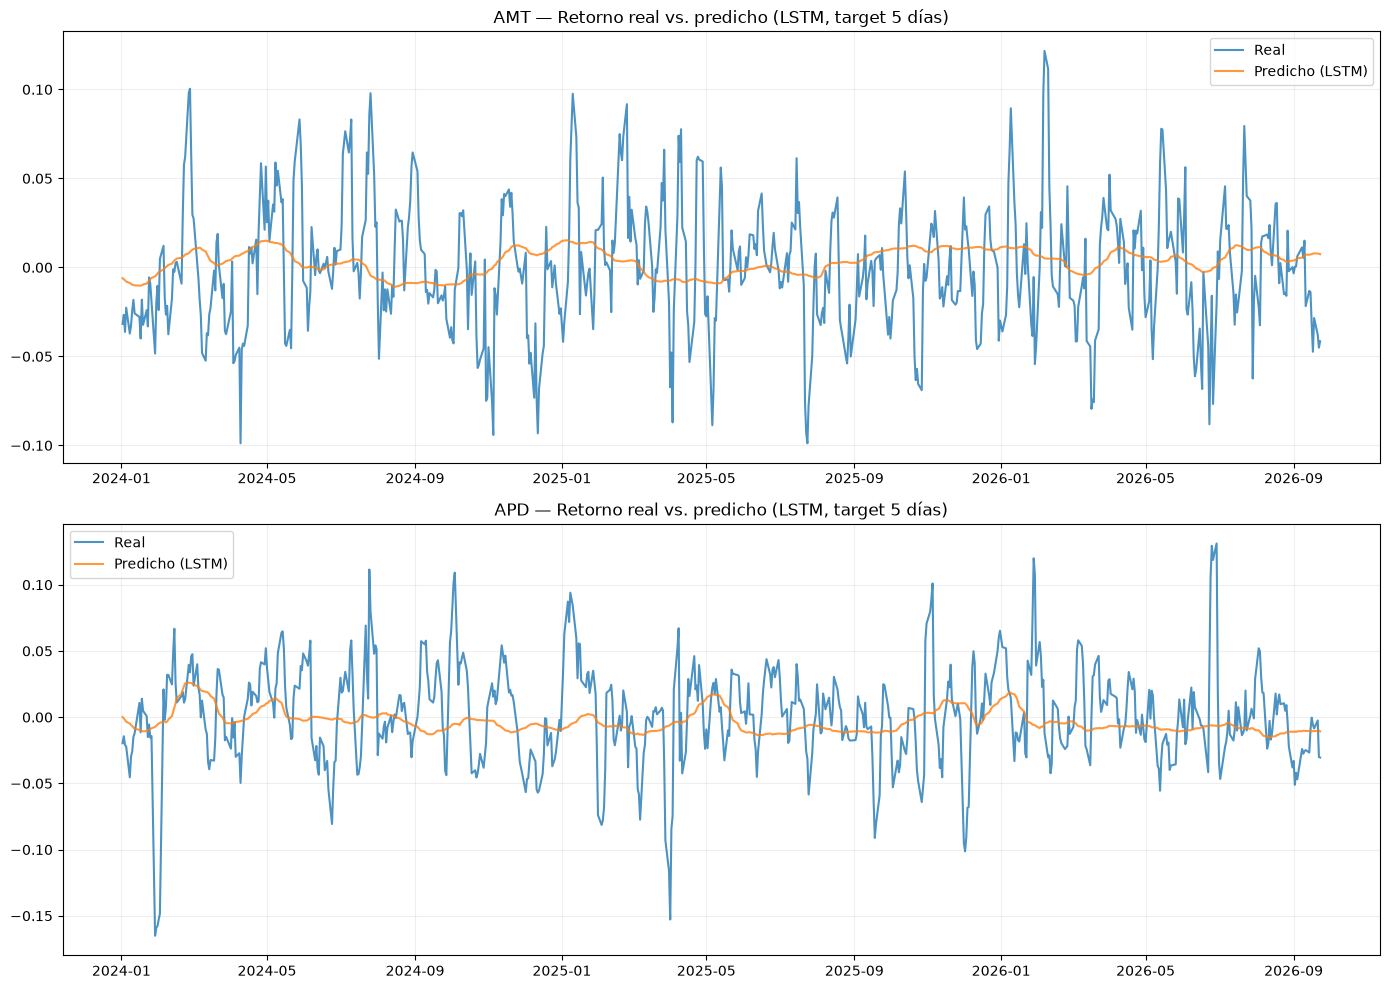

In [11]:
example_tickers_best = results_df.sort_values("R2", ascending=False).index[:2].tolist()

fig, axes = plt.subplots(len(example_tickers_best), 1, figsize=(14, 5 * len(example_tickers_best)))
if len(example_tickers_best) == 1:
    axes = [axes]

for ax, ticker in zip(axes, example_tickers_best):
    pred_df = predictions[ticker]
    ax.plot(pred_df["Date"], pred_df["actual"], label="Real", alpha=0.8)
    ax.plot(pred_df["Date"], pred_df["predicted"], label="Predicho (LSTM)", alpha=0.8)
    ax.set_title(f"{ticker} — Retorno real vs. predicho (LSTM, target 5 días)")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "03_predicho_vs_real.png", dpi=300, bbox_inches="tight")
plt.show()


## Vector de retornos esperados (mu_lstm)

Misma lógica de capitalización compuesta usada para `mu_svr`, para poder comparar de forma justa.

In [12]:
PERIODS_PER_YEAR = 252 / 5

mu_lstm = {}
for ticker, pred_df in predictions.items():
    mean_5d_return = pred_df["predicted"].mean()
    mu_lstm[ticker] = (1 + mean_5d_return) ** PERIODS_PER_YEAR - 1

mu_lstm = pd.Series(mu_lstm, name="mu_lstm").sort_values(ascending=False)

mu_lstm


NVDA     2.787804
UNH      0.620763
LIN      0.545405
XOM      0.440408
PEP      0.285066
DIS      0.284812
MSFT     0.172669
AMT      0.162326
PLD      0.086125
NEE      0.074989
D        0.054892
HON      0.013474
SPG      0.008174
HD      -0.012569
EQIX    -0.016590
JPM     -0.023179
MCD     -0.025803
COP     -0.025982
MA      -0.039011
CVX     -0.053383
KO      -0.062196
GOOGL   -0.062613
ECL     -0.066496
ABBV    -0.106455
META    -0.124472
LLY     -0.139992
APD     -0.160137
JNJ     -0.182773
V       -0.187242
PG      -0.257975
UNP     -0.263257
BAC     -0.267409
SO      -0.274109
DUK     -0.287884
AVGO    -0.317782
SHW     -0.340981
SLB     -0.370414
AMZN    -0.430173
WMT     -0.432239
TSLA    -0.476013
GE      -0.488557
CAT     -0.495794
NFLX    -0.504012
AAPL    -0.720720
Name: mu_lstm, dtype: float32

## Markowitz con mu_lstm (mismo procedimiento que con mu_svr)

Se corren las mismas dos variantes que en `05_svr_diversified.ipynb` (cota máxima 15% y 10%, ambas con cota mínima de 1%), para que SVR y LSTM se comparen en igualdad de condiciones.

In [13]:
from pypfopt.risk_models import CovarianceShrinkage
from pypfopt.efficient_frontier import EfficientFrontier

prices_for_mu = pd.read_csv(DATA_DIR / "adjusted_prices.csv", index_col=0, parse_dates=True)
asset_prices_lstm = prices_for_mu.drop(columns=[benchmark])

S_shrink_lstm = CovarianceShrinkage(asset_prices_lstm).ledoit_wolf()

# Variante 1: cota máxima 15% + cota mínima
ef_lstm = EfficientFrontier(mu_lstm, S_shrink_lstm, weight_bounds=(0, MAX_WEIGHT))
ef_lstm.add_constraint(lambda w: w >= MIN_WEIGHT)
raw_weights_lstm = ef_lstm.max_sharpe(risk_free_rate=0.02)
weights_lstm = ef_lstm.clean_weights()

print("=== Variante 1: max 15%, min 1% ===")
perf_lstm = ef_lstm.portfolio_performance(verbose=True, risk_free_rate=0.02)

# Variante 2: cota máxima 10% + cota mínima
ef_lstm_t = EfficientFrontier(mu_lstm, S_shrink_lstm, weight_bounds=(0, MAX_WEIGHT_TWO))
ef_lstm_t.add_constraint(lambda w: w >= MIN_WEIGHT)
raw_weights_lstm_t = ef_lstm_t.max_sharpe(risk_free_rate=0.02)
weights_lstm_t = ef_lstm_t.clean_weights()

print("\n=== Variante 2: max 10%, min 1% ===")
perf_lstm_t = ef_lstm_t.portfolio_performance(verbose=True, risk_free_rate=0.02)

pd.DataFrame({
    "max15%, min1%": pd.Series(weights_lstm),
    "max10%, min1%": pd.Series(weights_lstm_t)
}).sort_values("max15%, min1%", ascending=False)


=== Variante 1: max 15%, min 1% ===
Expected annual return: 59.2%
Annual volatility: 18.4%
Sharpe Ratio: 3.11

=== Variante 2: max 10%, min 1% ===
Expected annual return: 41.9%
Annual volatility: 18.1%
Sharpe Ratio: 2.20


,"max15%, min1%","max10%, min1%"
NVDA,0.1500,0.10000
UNH,0.1500,0.10000
LIN,0.1500,0.10000
XOM,0.1065,0.10000
PEP,0.0535,0.10000
DIS,0.0100,0.04514
MSFT,0.0100,0.01000
AMT,0.0100,0.01873
PLD,0.0100,0.01000
NEE,0.0100,0.01000


### Composición sectorial de los portafolios Markowitz + LSTM

Agrupa los pesos óptimos por sector para ambas variantes y los compara contra Equal Weight.

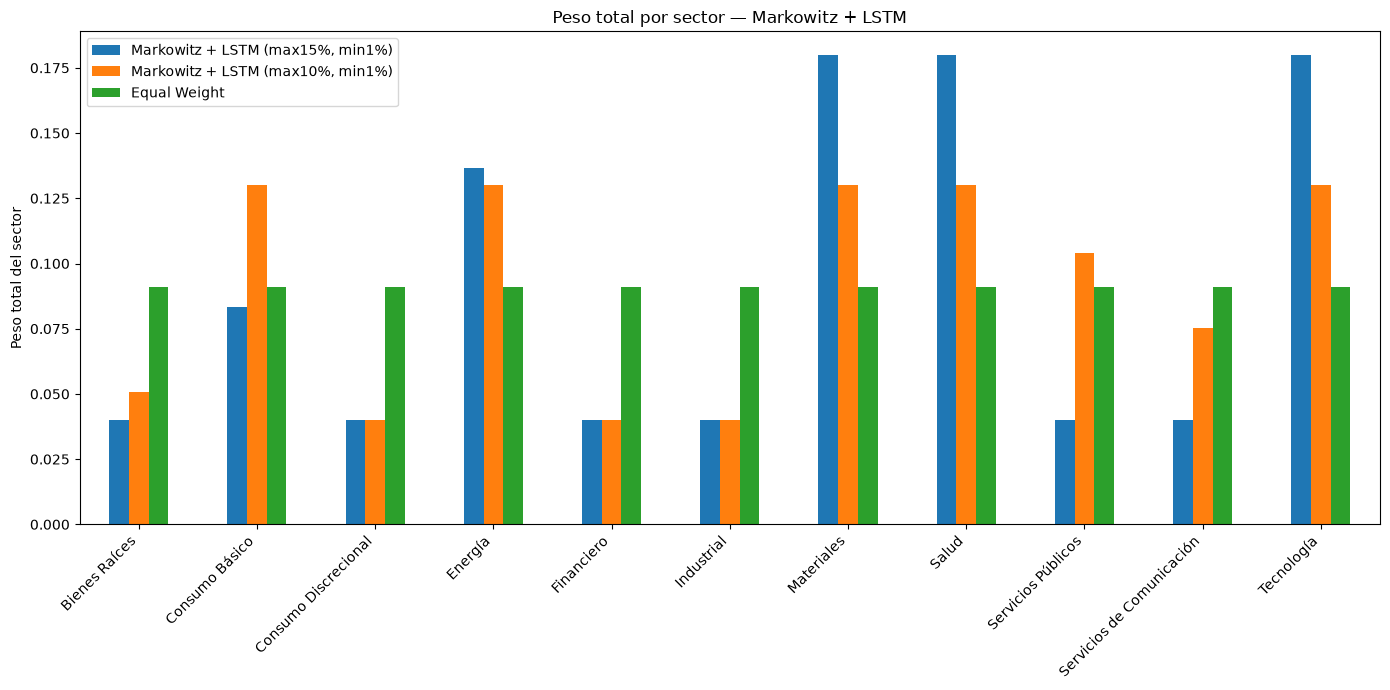

,"Markowitz + LSTM (max15%, min1%)","Markowitz + LSTM (max10%, min1%)",Equal Weight
Bienes Raíces,0.0400,0.0508,0.0909
Consumo Básico,0.0835,0.1300,0.0909
Consumo Discrecional,0.0400,0.0400,0.0909
Energía,0.1365,0.1300,0.0909
Financiero,0.0400,0.0400,0.0909
Industrial,0.0400,0.0400,0.0909
Materiales,0.1800,0.1300,0.0909
Salud,0.1800,0.1300,0.0909
Servicios Públicos,0.0400,0.1041,0.0909
Servicios de Comunicación,0.0400,0.0751,0.0909


In [14]:
weights_equal_sector = pd.Series(
    1 / len(asset_prices_lstm.columns), index=asset_prices_lstm.columns
).to_dict()

sector_weights_lstm = pd.DataFrame({
    "Markowitz + LSTM (max15%, min1%)": weights_by_sector(weights_lstm),
    "Markowitz + LSTM (max10%, min1%)": weights_by_sector(weights_lstm_t),
    "Equal Weight": weights_by_sector(weights_equal_sector)
}).fillna(0)

sector_weights_lstm.plot(kind="bar", figsize=(14, 7), title="Peso total por sector — Markowitz + LSTM")
plt.ylabel("Peso total del sector")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "05_composicion_sectorial_lstm.png", dpi=300, bbox_inches="tight")
plt.show()

sector_weights_lstm.round(4)


## Backtest: Markowitz + LSTM vs. las demás estrategias

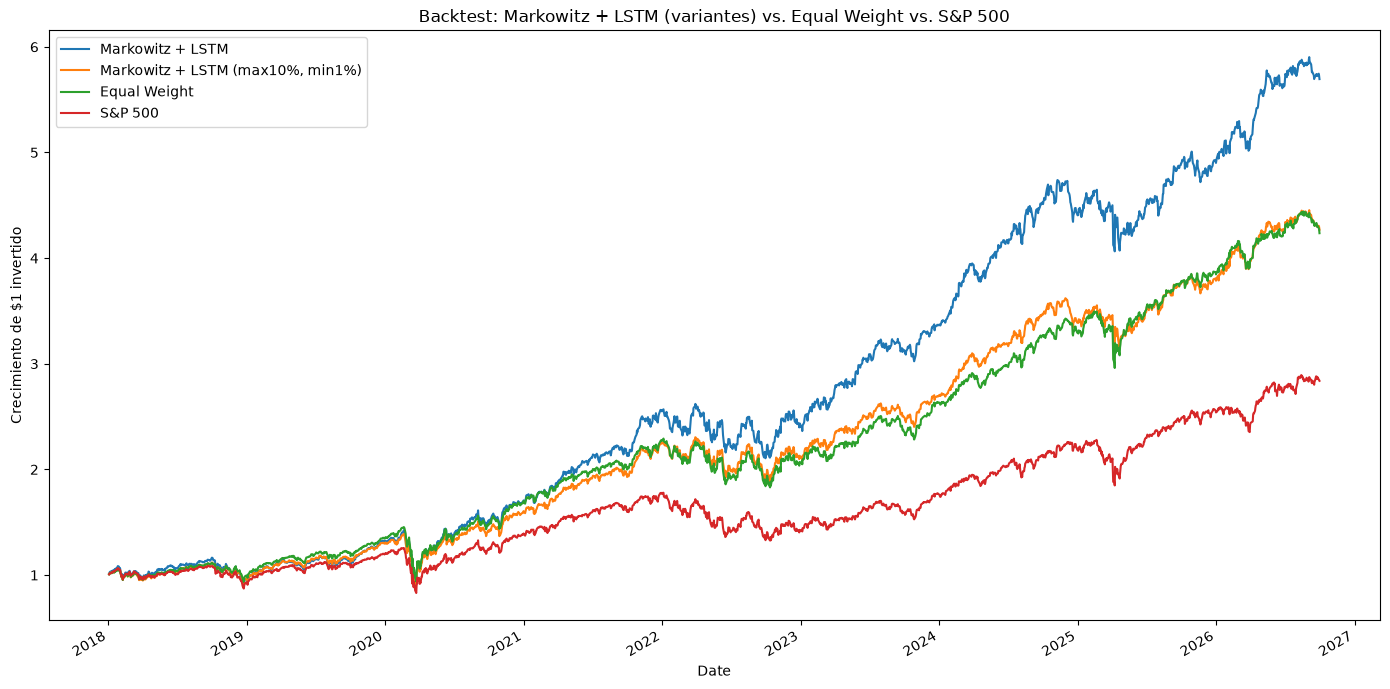

In [15]:
returns_for_backtest = pd.read_csv(DATA_DIR / "daily_returns.csv", index_col=0, parse_dates=True)
returns_for_backtest.index.name = "Date"
returns_for_backtest_clean = returns_for_backtest.dropna(how="all")
asset_returns_lstm = returns_for_backtest_clean.drop(columns=[benchmark])

def portfolio_cumulative_return(weights: pd.Series, returns: pd.DataFrame) -> pd.Series:
    aligned_weights = weights.reindex(returns.columns).fillna(0)
    portfolio_returns = (returns * aligned_weights).sum(axis=1)
    return (1 + portfolio_returns).cumprod()

n_assets = len(asset_returns_lstm.columns)
weights_equal_lstm = pd.Series(1 / n_assets, index=asset_returns_lstm.columns)

comparison_lstm = pd.DataFrame({
    "Markowitz + LSTM": portfolio_cumulative_return(pd.Series(weights_lstm), asset_returns_lstm),
    "Markowitz + LSTM (max10%, min1%)": portfolio_cumulative_return(pd.Series(weights_lstm_t), asset_returns_lstm),
    "Equal Weight": portfolio_cumulative_return(weights_equal_lstm, asset_returns_lstm),
    "S&P 500": (1 + returns_for_backtest_clean[benchmark]).cumprod()
})

comparison_lstm.plot(figsize=(14, 7), title="Backtest: Markowitz + LSTM (variantes) vs. Equal Weight vs. S&P 500")
plt.ylabel("Crecimiento de $1 invertido")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "04_backtest_markowitz_lstm.png", dpi=300, bbox_inches="tight")
plt.show()


## Tabla resumen de métricas

Para la comparación completa, agrega manualmente las filas de Markowitz clásico y Markowitz + SVR con los valores de `04_markowitz_diversified.ipynb` y `05_svr_diversified.ipynb` (no uses los del universo original de 20 activos).

In [16]:
def annualized_metrics(cum_returns: pd.Series, risk_free_rate: float = 0.02) -> dict:
    daily_returns = cum_returns.pct_change().dropna()
    ann_return = daily_returns.mean() * 252
    ann_vol = daily_returns.std() * np.sqrt(252)
    sharpe = (ann_return - risk_free_rate) / ann_vol
    max_drawdown = (cum_returns / cum_returns.cummax() - 1).min()
    return {
        "Retorno anualizado": ann_return,
        "Volatilidad anualizada": ann_vol,
        "Sharpe Ratio": sharpe,
        "Máximo Drawdown": max_drawdown
    }

summary_lstm = pd.DataFrame({
    col: annualized_metrics(comparison_lstm[col]) for col in comparison_lstm.columns
}).T

summary_lstm.round(4)


,Retorno anualizado,Volatilidad anualizada,Sharpe Ratio,Máximo Drawdown
Markowitz + LSTM,0.2181,0.2011,0.9855,-0.3536
"Markowitz + LSTM (max10%, min1%)",0.1828,0.1853,0.8783,-0.3502
Equal Weight,0.1818,0.1826,0.8860,-0.3542
S&P 500,0.1374,0.1914,0.6133,-0.3392


## Guardar resultados

In [17]:
results_df.to_csv(RESULTS_DIR / "lstm_performance_by_ticker.csv")
mu_lstm.to_csv(RESULTS_DIR / "mu_lstm.csv")
pd.Series(weights_lstm).to_csv(RESULTS_DIR / "weights_markowitz_lstm.csv")
pd.Series(weights_lstm_t).to_csv(RESULTS_DIR / "weights_markowitz_lstm_max10.csv")
comparison_lstm.to_csv(RESULTS_DIR / "backtest_markowitz_lstm.csv")
summary_lstm.to_csv(RESULTS_DIR / "summary_markowitz_lstm.csv")

print("Resultados guardados en:", RESULTS_DIR)


Resultados guardados en: c:\Users\ofeli\Documents\GitHub\Portafolio_investigacion\results\lstm_diversified
